# Modelo de Clasificación mediante Árboles de Decisión

## 1. Introducción

Un árbol de decisión clasifica observaciones mediante reglas sucesivas sobre sus características. Cada división separa casos con perfiles distintos y termina en una hoja con una clase estimada. En este trabajo se aplica a viviendas registradas en los microdatos del Censo de Población y Vivienda 2024 del INE Bolivia para reconocer patrones asociados con carencias de servicios básicos. Las reglas son descriptivas del modelo y no establecen causas.

## 2. Definición del problema

La variable objetivo **`vivienda_precaria`** vale **0** cuando se identifican cero o una carencia y **1** cuando se identifican dos o más. Se consideran agua, saneamiento, electricidad e internet. La clase solo se asigna si las cuatro dimensiones pueden evaluarse. Se eligió esta variable porque resume en una clase binaria la acumulación de carencias, que es el problema de clasificación planteado. El umbral de dos carencias diferencia a las viviendas con privaciones simultáneas de aquellas con cero o una. Esta clasificación y el Índice de Precariedad de Servicios (IPS) son **definiciones operativas del proyecto**, no indicadores oficiales publicados por el INE.

El árbol permite estudiar combinaciones de características de la vivienda con reglas legibles. Se usará para clasificar registros con una definición ya establecida, no para medir el efecto causal de las características sobre los servicios.

## 3. Selección de variables independientes

Se conservan los diez predictores usados en el modelado previo. La tabla utiliza las descripciones de la hoja `VIVIENDA` del diccionario oficial. Todos se tratan como categóricos, incluidos los conteos de habitaciones y dormitorios, para respetar la codificación del proyecto. `urbrur` representa área urbana o rural; no se incluyen códigos de departamento o municipio, por lo que aquí no se estima la capacidad de generalización a territorios no vistos.

In [1]:
from pathlib import Path
import gc
import sys
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"font.size":10,"axes.titlesize":13,"figure.dpi":115})
FUENTE = "Fuente: elaboración propia con microdatos del Censo 2024, INE Bolivia."
FUENTE_PRUEBA = "Fuente: elaboración propia. Conjunto de prueba; microdatos del Censo 2024, INE Bolivia."
FUENTE_ENTRENAMIENTO = "Fuente: elaboración propia. Modelo ajustado con entrenamiento; microdatos del Censo 2024, INE Bolivia."
DATA = Path("data")
CSV = DATA / "Vivienda_CPV-2024.csv"
DICCIONARIO = DATA / "Diccionario de variables CPV 2024.xlsx"
assert CSV.is_file() and DICCIONARIO.is_file(), "Los archivos oficiales deben estar en data/."
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)

predictoras = ["urbrur", "v01_tipoviv", "v03_pared", "v05_techo", "v06_piso",
               "v11_basura", "v13_habitac", "v14_dormit", "v17_tenencia", "tip_hog"]
fuentes_objetivo = ["v07_aguapro", "v15_servsan", "v16_desague", "v09_energia", "v19e_f"]
columnas_csv = pd.read_csv(CSV, sep=";", encoding="utf-8-sig", nrows=0).columns.tolist()
assert len(columnas_csv) == 48, "El CSV difiere del archivo revisado; comprobar antes de seguir."
assert set(predictoras + fuentes_objetivo).issubset(columnas_csv)

fichas = {}
tabla_dic = pd.read_excel(DICCIONARIO, sheet_name="VIVIENDA", header=None, dtype="string")
descripcion, actual = "", None
for fila in tabla_dic.itertuples(index=False, name=None):
    clave = str(fila[1]).strip() if pd.notna(fila[1]) else ""
    dato = str(fila[2]).strip() if pd.notna(fila[2]) else ""
    if clave == "Etiqueta":
        descripcion = dato
    elif clave == "Nombre":
        actual = dato.lower()
        fichas[actual] = {"descripcion": descripcion, "categorias": {}}
    elif actual is not None and clave not in ("", "Categorías", "Tipo") and pd.notna(fila[2]):
        fichas[actual]["categorias"][clave] = dato
assert all(c in fichas for c in predictoras)

justificacion = {
    "urbrur":"Contexto urbano/rural; no forma parte del objetivo",
    "v01_tipoviv":"Tipo de vivienda",
    "v03_pared":"Material predominante de pared",
    "v05_techo":"Material predominante de techo",
    "v06_piso":"Material predominante de piso",
    "v11_basura":"Práctica de eliminación de basura",
    "v13_habitac":"Número categorizado de habitaciones",
    "v14_dormit":"Número categorizado de dormitorios",
    "v17_tenencia":"Condición de tenencia",
    "tip_hog":"Tipología de hogar documentada",
}
tabla_variables = pd.DataFrame([{
    "Variable": c, "Descripción": fichas[c]["descripcion"],
    "Tipo": "Categórica", "Justificación": justificacion[c]
} for c in predictoras])
display(tabla_variables)
print("Nota: las categorías y sus códigos se toman de la hoja VIVIENDA del diccionario oficial.")

Python: 3.14.4 | pandas: 3.0.6 | scikit-learn: 1.9.1


,Variable,Descripción,Tipo,Justificación
0,urbrur,Área Urbana - Rural,Categórica,Contexto urbano/rural; no forma parte del obje...
1,v01_tipoviv,1. La vivienda es: (Tipo de vivienda),Categórica,Tipo de vivienda
2,v03_pared,3. Cual es el material de construcción más uti...,Categórica,Material predominante de pared
3,v05_techo,5. Cuál es el material de construcción más uti...,Categórica,Material predominante de techo
4,v06_piso,6. Cuál es el material más utilizado en los pi...,Categórica,Material predominante de piso
5,v11_basura,11. Habitualmente. Qué hacen con la basura que...,Categórica,Práctica de eliminación de basura
6,v13_habitac,"13. Cuántos cuartos o habitaciones ocupan, sin...",Categórica,Número categorizado de habitaciones
7,v14_dormit,"14. De estos cuartos o habitaciones, Cuántos s...",Categórica,Número categorizado de dormitorios
8,v17_tenencia,17. La vivienda que ocupan es: (Tenencia de la...,Categórica,Condición de tenencia
9,tip_hog,Tipología de hogar,Categórica,Tipología de hogar documentada


Nota: las categorías y sus códigos se toman de la hoja VIVIENDA del diccionario oficial.


In [2]:
carencias = ["carencia_agua", "carencia_saneamiento", "carencia_electricidad", "carencia_internet"]
excluidas_directas = set(fuentes_objetivo + ["v19e_inetfijo", "v19f_inetmovil", "v08_aguadist",
                "v10_combus", "i00", "idep", "iprov", "imun", "n_carencias", "vivienda_precaria"] + carencias)
excluidas_proximas = {c for c in columnas_csv if c.startswith(("v18", "v19"))}
assert not set(predictoras) & (excluidas_directas | excluidas_proximas)
print("Intersección entre predictores y variables excluidas:",
      set(predictoras) & (excluidas_directas | excluidas_proximas))

Intersección entre predictores y variables excluidas: set()


Las cuatro carencias, su suma, la clase y las preguntas censales que las generan quedan excluidas de `X`. También se excluyen identificadores, códigos territoriales y variables muy próximas a agua, electricidad o internet. Esta separación evita que el modelo reciba la respuesta como predictor.

## 4. Preparación de los datos

Se leen únicamente las columnas necesarias del archivo oficial. La población analítica reproduce el filtrado de `entendimiento de datos.ipynb`: viviendas particulares de tipos 1 a 6, ocupadas con personas presentes (`v02_condocup` 0 o 1), con al menos una persona y con las preguntas básicas aplicables. Los códigos que no permiten clasificar alguna carencia permanecen sin clase; no se convierten de forma arbitraria en acceso o falta de acceso.

In [3]:
columnas_lectura = list(dict.fromkeys(["v01_tipoviv", "v02_condocup", "tot_pers"] + fuentes_objetivo + predictoras))
df_base = pd.read_csv(CSV, sep=";", encoding="utf-8-sig", usecols=columnas_lectura,
                      dtype={c:"category" for c in columnas_lectura})
assert len(df_base) == 4_490_488, "El número de filas originales cambió."
particular = df_base["v01_tipoviv"].astype("string").isin({"1","2","3","4","5","6"})
presente = df_base["v02_condocup"].astype("string").isin({"0","1"})
con_personas = pd.to_numeric(df_base["tot_pers"].astype("string"), errors="coerce").gt(0)
aplica = df_base[["v07_aguapro","v15_servsan","v09_energia","v19e_f"]].notna().all(axis=1)
df_analisis = df_base.loc[particular & presente & con_personas & aplica].copy()
assert len(df_analisis) == 3_623_711, "La población analítica no coincide con el análisis previo."
display(pd.DataFrame({"Etapa":["CSV original", "Viviendas analíticas"],
                      "Registros":[len(df_base),len(df_analisis)]}))
del df_base, particular, presente, con_personas, aplica
_ = gc.collect()

,Etapa,Registros
0,CSV original,4490488
1,Viviendas analíticas,3623711


Las reglas de carencia son las ya documentadas en el proyecto: agua sin carencia para códigos 1, 2, 4 y 6, con carencia para 5 y 7; saneamiento sin carencia para baño 1 con desagüe 1, 2 o 6, con carencia para baño 2 o 3, o baño 1 con desagüe 5; electricidad sin carencia para 1 a 4 y con carencia para 5; internet sin carencia para 1 y con carencia para 2. Las respuestas restantes quedan indeterminadas. La clase se define solo en registros con las cuatro carencias válidas.

In [4]:
def indicador(index, reglas):
    resultado = pd.Series(pd.NA, index=index, dtype="Int8")
    for condicion, valor in reglas:
        resultado.loc[condicion.fillna(False)] = valor
    return resultado

agua = df_analisis["v07_aguapro"].astype("string")
san = df_analisis["v15_servsan"].astype("string")
des = df_analisis["v16_desague"].astype("string")
elec = df_analisis["v09_energia"].astype("string")
inet = df_analisis["v19e_f"].astype("string")
df_analisis["carencia_agua"] = indicador(df_analisis.index, [
    (agua.isin({"1","2","4","6"}),0), (agua.isin({"5","7"}),1)])
df_analisis["carencia_saneamiento"] = indicador(df_analisis.index, [
    ((san=="1") & des.isin({"1","2","6"}),0),
    (san.isin({"2","3"}) | ((san=="1") & (des=="5")),1)])
df_analisis["carencia_electricidad"] = indicador(df_analisis.index, [
    (elec.isin({"1","2","3","4"}),0), (elec=="5",1)])
df_analisis["carencia_internet"] = indicador(df_analisis.index, [
    (inet=="1",0), (inet=="2",1)])

completas = df_analisis[carencias].notna().all(axis=1)
df_objetivo = df_analisis.loc[completas, predictoras + carencias].copy()
df_objetivo["n_carencias"] = df_objetivo[carencias].sum(axis=1).astype("int8")
df_objetivo["vivienda_precaria"] = (df_objetivo["n_carencias"]>=2).astype("int8")
assert len(df_objetivo)==2_635_157, "La población con objetivo cambió."
ips_observado = 100*df_objetivo["vivienda_precaria"].mean()
assert round(ips_observado,2)==19.60, "El IPS no coincide con el notebook de entendimiento."
resumen_poblacion = pd.DataFrame({"Etapa":["Viviendas analíticas", "Objetivo clasificable", "Sin objetivo clasificable"],
 "Viviendas":[len(df_analisis),len(df_objetivo),len(df_analisis)-len(df_objetivo)]})
display(resumen_poblacion)
print(f"Cobertura: {100*len(df_objetivo)/len(df_analisis):.2f}% | IPS: {ips_observado:.2f}%")
del df_analisis, completas, agua, san, des, elec, inet
_ = gc.collect()

,Etapa,Viviendas
0,Viviendas analíticas,3623711
1,Objetivo clasificable,2635157
2,Sin objetivo clasificable,988554


Cobertura: 72.72% | IPS: 19.60%


In [5]:
faltantes_predictores = df_objetivo[predictoras].isna().sum()
display(pd.DataFrame({"Variable":predictoras,
                      "Valores faltantes":[int(faltantes_predictores[c]) for c in predictoras],
                      "Categorías observadas":[int(df_objetivo[c].nunique()) for c in predictoras]}))
assert faltantes_predictores.eq(0).all(), "Hay faltantes: revisar e incorporar imputación dentro del Pipeline."
print("No se requiere imputación en los predictores de la población modelada.")

,Variable,Valores faltantes,Categorías observadas
0,urbrur,0,2
1,v01_tipoviv,0,6
2,v03_pared,0,7
3,v05_techo,0,5
4,v06_piso,0,9
5,v11_basura,0,7
6,v13_habitac,0,8
7,v14_dormit,0,9
8,v17_tenencia,0,8
9,tip_hog,0,8


No se requiere imputación en los predictores de la población modelada.


La revisión muestra si se necesita imputación. La codificación One-Hot se ajusta dentro del `Pipeline` con el conjunto de entrenamiento de cada ajuste; una categoría no vista en prueba no provoca error. Se mantiene la división estratificada 80/20 y `random_state=42`, igual que en el modelado anterior. El conjunto de prueba queda separado de toda selección de hiperparámetros.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = df_objetivo[predictoras].copy()
y = df_objetivo["vivienda_precaria"].copy()
assert not set(X.columns) & (excluidas_directas | excluidas_proximas)
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.20,random_state=42,stratify=y)
assert X_train.index.intersection(X_test.index).empty
assert len(X_train)+len(X_test)==len(X)

def tabla_clases(nombre, serie):
    conteos = serie.value_counts().sort_index()
    return pd.DataFrame({"Conjunto":nombre,"Clase":conteos.index,
                         "Viviendas":conteos.values,
                         "Porcentaje":(100*conteos/len(serie)).round(2).values})
distribucion = pd.concat([tabla_clases(n,s) for n,s in [
    ("Total",y),("Entrenamiento",y_train),("Prueba",y_test)]],ignore_index=True)
display(distribucion)
print("N total:",len(X),"| N entrenamiento:",len(X_train),"| N prueba:",len(X_test))

def preparar():
    return ColumnTransformer([
        ("categoricas",OneHotEncoder(handle_unknown="ignore",drop="first",
                                    sparse_output=True,dtype=np.float32),predictoras)
    ],sparse_threshold=1.0)

,Conjunto,Clase,Viviendas,Porcentaje
0,Total,0,2118663,80.4
1,Total,1,516494,19.6
2,Entrenamiento,0,1694930,80.4
3,Entrenamiento,1,413195,19.6
4,Prueba,0,423733,80.4
5,Prueba,1,103299,19.6


N total: 2635157 | N entrenamiento: 2108125 | N prueba: 527032


In [7]:
del df_objetivo, X
_ = gc.collect()

## 5. Fundamento teórico del árbol de decisión

Un **nodo** agrupa casos antes de una decisión; una **rama** representa el resultado de esa decisión; una **hoja** es un nodo final que asigna una clase. En cada división, el algoritmo busca una variable y un umbral que reduzcan la mezcla de clases. La **profundidad** es el número de divisiones desde la raíz hasta una hoja. Si se permiten demasiadas divisiones, el árbol puede ajustar particularidades del entrenamiento y rendir peor en datos no vistos: esto es **sobreajuste**.

Para un nodo con proporción $p_k$ de la clase $k$, la impureza de Gini y la entropía son:

$$G = 1 - \sum_{k=1}^{K} p_k^2$$

$$H = -\sum_{k=1}^{K} p_k \log_2(p_k), \qquad 0\log_2(0)=0$$

Ambas valen cero en un nodo puro. Se toma **Gini** como criterio principal por continuidad con el modelado previo y se compara con entropía en la validación. La profundidad, el mínimo de muestras por división y el mínimo por hoja limitan la complejidad.

## 6. Entrenamiento del modelo inicial

Como referencia se entrena un `DecisionTreeClassifier(random_state=42)` sobre el entrenamiento completo. Todos sus **hiperparámetros de aprendizaje conservan los valores predeterminados** de scikit-learn: el árbol no tiene límite explícito de profundidad ni mínimo de hoja adicional. El modelo elige en cada nodo la división que más reduce la impureza de Gini. Esta referencia permite observar el desempeño y la complejidad antes de regular el árbol. `random_state=42` solo fija la reproducibilidad de decisiones equivalentes.

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

def construir_arbol(parametros=None):
    return Pipeline([
        ("preprocesamiento", preparar()),
        ("clasificador", DecisionTreeClassifier(random_state=42, **(parametros or {})))
    ])

modelo_inicial = construir_arbol()
modelo_inicial.fit(X_train, y_train)
arbol_inicial = modelo_inicial.named_steps["clasificador"]
parametros_iniciales = arbol_inicial.get_params()
display(pd.DataFrame({"Hiperparámetro": ["criterion", "max_depth", "min_samples_split",
                                          "min_samples_leaf", "class_weight", "ccp_alpha", "random_state"],
                      "Valor": [str(parametros_iniciales[k]) for k in
                                ["criterion", "max_depth", "min_samples_split", "min_samples_leaf",
                                 "class_weight", "ccp_alpha", "random_state"]]}))
print("Profundidad observada:", arbol_inicial.get_depth(),
      "| Hojas observadas:", arbol_inicial.get_n_leaves())

,Hiperparámetro,Valor
0,criterion,gini
1,max_depth,None
2,min_samples_split,2
3,min_samples_leaf,1
4,class_weight,None
5,ccp_alpha,0.0
6,random_state,42


Profundidad observada: 54 | Hojas observadas: 88803


## 7. Ajuste de hiperparámetros

Se separa el 20 % **del entrenamiento** como validación interna, con estratificación. Primero se mide el árbol predeterminado en esa partición. Luego se comparan pocas configuraciones acotadas que modifican **profundidad máxima**, **criterio de división** y **muestras mínimas por hoja**; `min_samples_split` también se controla. Algunas usan `class_weight="balanced"` para atender la menor frecuencia de la clase 1 y otras conservan los pesos predeterminados. `ccp_alpha=0` porque la complejidad ya se restringe con los otros parámetros.

La selección utiliza **F1 de la clase 1 en validación**, que combina precisión y recuperación. Si dos configuraciones empatan, se prefiere la de menor profundidad y menor número de hojas. El conjunto de prueba no interviene en la selección. Después se vuelve a entrenar la configuración elegida con todo el entrenamiento.

In [9]:
X_ajuste, X_val, y_ajuste, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train)
assert X_ajuste.index.intersection(X_val.index).empty
assert X_test.index.intersection(X_ajuste.index).empty
assert X_test.index.intersection(X_val.index).empty

base_ajustada = dict(criterion="gini", max_depth=3, min_samples_split=10000,
                     min_samples_leaf=5000, class_weight="balanced", ccp_alpha=0.0)
configuraciones = [
    ("Inicial predeterminado", {}),
    ("Gini, prof. 5, hoja 10000, ponderado", dict(base_ajustada, max_depth=5,
                                      min_samples_leaf=10000, min_samples_split=20000)),
    ("Gini, prof. 10, hoja 500", dict(criterion="gini", max_depth=10,
                                      min_samples_leaf=500, min_samples_split=1000)),
    ("Entropía, prof. 10, hoja 500", dict(criterion="entropy", max_depth=10,
                                         min_samples_leaf=500, min_samples_split=1000)),
    ("Gini, prof. 15, hoja 1000", dict(criterion="gini", max_depth=15,
                                       min_samples_leaf=1000, min_samples_split=2000)),
]
resultados_validacion = []
for nombre, parametros in configuraciones:
    candidato = construir_arbol(parametros)
    candidato.fit(X_ajuste, y_ajuste)
    ajuste_pred = candidato.predict(X_ajuste)
    val_pred = candidato.predict(X_val)
    arbol_candidato = candidato.named_steps["clasificador"]
    resultados_validacion.append({
        "Configuración": nombre, "Parámetros": parametros,
        "F1 ajuste": f1_score(y_ajuste, ajuste_pred),
        "F1 validación": f1_score(y_val, val_pred),
        "Recall validación": recall_score(y_val, val_pred),
        "Profundidad": arbol_candidato.get_depth(),
        "Hojas": arbol_candidato.get_n_leaves()
    })
    del candidato
tabla_validacion = pd.DataFrame(resultados_validacion)
display(tabla_validacion.drop(columns="Parámetros").round(4))
mejor_fila = tabla_validacion.sort_values(
    ["F1 validación", "Profundidad", "Hojas"], ascending=[False, True, True]).iloc[0]
parametros_finales = mejor_fila["Parámetros"]
print("Seleccionado por validación:", mejor_fila["Configuración"])
print("Parámetros seleccionados:", parametros_finales or "Predeterminados; solo random_state=42")
print("Brecha F1 ajuste-validación:",
      round(float(mejor_fila["F1 ajuste"] - mejor_fila["F1 validación"]), 4))

modelo_final = construir_arbol(parametros_finales)
modelo_final.fit(X_train, y_train)
arbol_final = modelo_final.named_steps["clasificador"]
print("Árbol final: profundidad", arbol_final.get_depth(),
      "| hojas", arbol_final.get_n_leaves())
del X_ajuste, X_val, y_ajuste, y_val
_ = gc.collect()

,Configuración,F1 ajuste,F1 validación,Recall validación,Profundidad,Hojas
0,Inicial predeterminado,0.7492,0.7028,0.6780,55,77725
1,"Gini, prof. 5, hoja 10000, ponderado",0.7022,0.7010,0.7995,5,21
2,"Gini, prof. 10, hoja 500",0.7065,0.7039,0.6730,10,331
3,"Entropía, prof. 10, hoja 500",0.7063,0.7037,0.6737,10,323
4,"Gini, prof. 15, hoja 1000",0.7072,0.7047,0.6717,15,479


Seleccionado por validación: Gini, prof. 15, hoja 1000
Parámetros seleccionados: {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 1000, 'min_samples_split': 2000}
Brecha F1 ajuste-validación: 0.0025


Árbol final: profundidad 15 | hojas 548


La tabla anterior compara **solo el entrenamiento interno y la validación interna**. El árbol predeterminado permite apreciar si la complejidad libre favorece el ajuste de casos particulares. Una caída de F1 entre ajuste y validación es una señal de sobreajuste. La prueba se usa únicamente después de seleccionar y reentrenar la configuración final.

In [10]:
fila_base = tabla_validacion.loc[
    tabla_validacion["Configuración"] == "Inicial predeterminado"].iloc[0]
mejora_val = float(mejor_fila["F1 validación"] - fila_base["F1 validación"])
brecha_base = float(fila_base["F1 ajuste"] - fila_base["F1 validación"])
brecha_final = float(mejor_fila["F1 ajuste"] - mejor_fila["F1 validación"])
display(Markdown(
    f"En **validación interna**, el árbol predeterminado obtuvo **F1={fila_base['F1 validación']:.4f}** "
    f"y el seleccionado **F1={mejor_fila['F1 validación']:.4f}** "
    f"(diferencia {mejora_val:+.4f}). La brecha F1 entre ajuste y validación fue "
    f"**{brecha_base:.4f}** para el predeterminado y **{brecha_final:.4f}** para el seleccionado. "
    + ("La brecha se redujo." if brecha_final < brecha_base else
       "La brecha no se redujo; esto limita la conclusión sobre control de sobreajuste.")
))

En **validación interna**, el árbol predeterminado obtuvo **F1=0.7028** y el seleccionado **F1=0.7047** (diferencia +0.0019). La brecha F1 entre ajuste y validación fue **0.0464** para el predeterminado y **0.0025** para el seleccionado. La brecha se redujo.

## 8. Evaluación del modelo

Tras fijar los parámetros, se calculan las métricas de ambos árboles sobre la misma prueba reservada para informar la comparación final; esos resultados no intervienen en la selección. La evaluación principal corresponde al árbol ajustado. La clase positiva es `1 = vivienda precaria`. Accuracy indica proporción total de aciertos; precision, la fracción de predicciones positivas correctas; recall, la fracción de positivos reales detectados; F1 resume precision y recall; ROC-AUC mide ordenación de los casos según la puntuación del modelo a distintos umbrales. El IPS es una proporción descriptiva de viviendas con clase 1 y **no** una métrica predictiva.

In [11]:
def evaluar_modelo(nombre, modelo, X_datos, y_datos):
    pred = modelo.predict(X_datos)
    prob = modelo.predict_proba(X_datos)[:, 1]
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_datos, pred),
        "Precision": precision_score(y_datos, pred),
        "Recall": recall_score(y_datos, pred),
        "F1": f1_score(y_datos, pred),
        "ROC-AUC": roc_auc_score(y_datos, prob)
    }

metricas_train_final = evaluar_modelo("Final: entrenamiento", modelo_final, X_train, y_train)
metricas_test_inicial = evaluar_modelo("Predeterminado: prueba", modelo_inicial, X_test, y_test)
metricas_test_final = evaluar_modelo("Final: prueba", modelo_final, X_test, y_test)
tabla_metricas = pd.DataFrame([metricas_train_final, metricas_test_inicial,
                               metricas_test_final]).set_index("Modelo")
display(tabla_metricas.round(4))
pred_final = modelo_final.predict(X_test)
prob_final = modelo_final.predict_proba(X_test)[:, 1]
cm_final = confusion_matrix(y_test, pred_final, labels=[0, 1])
tn, fp, fn, tp = cm_final.ravel()
display(pd.DataFrame(cm_final, index=["Real 0", "Real 1"],
                     columns=["Predicha 0", "Predicha 1"]))
print("Classification report — conjunto de prueba")
print(classification_report(y_test, pred_final, target_names=["No precaria (0)", "Precaria (1)"], digits=4))
assert tn + fp + fn + tp == len(y_test)
assert abs(metricas_test_final["Recall"] - tp / (tp + fn)) < 1e-12

,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Final: entrenamiento,0.8905,0.7435,0.6739,0.7070,0.9270
Predeterminado: prueba,0.8889,0.7332,0.6811,0.7062,0.9022
Final: prueba,0.8903,0.7437,0.6722,0.7061,0.9273


,Predicha 0,Predicha 1
Real 0,399803,23930
Real 1,33863,69436


Classification report — conjunto de prueba
                 precision    recall  f1-score   support

No precaria (0)     0.9219    0.9435    0.9326    423733
   Precaria (1)     0.7437    0.6722    0.7061    103299

       accuracy                         0.8903    527032
      macro avg     0.8328    0.8079    0.8194    527032
   weighted avg     0.8870    0.8903    0.8882    527032



In [12]:
display(Markdown(
    f"En las **{len(y_test):,} viviendas de prueba**, el árbol final alcanzó "
    f"**accuracy {metricas_test_final['Accuracy']:.4f}**, "
    f"**precision {metricas_test_final['Precision']:.4f}**, "
    f"**recall {metricas_test_final['Recall']:.4f}**, "
    f"**F1 {metricas_test_final['F1']:.4f}** y "
    f"**ROC-AUC {metricas_test_final['ROC-AUC']:.4f}**. "
    f"La matriz registra **{tp:,} verdaderos positivos**, **{tn:,} verdaderos negativos**, "
    f"**{fp:,} falsos positivos** y **{fn:,} falsos negativos**. "
    "Estos últimos corresponden a viviendas con al menos dos carencias que el modelo no detectó; "
    "son especialmente relevantes si se usa la predicción para priorizar una revisión adicional. "
    f"La diferencia F1 entre entrenamiento completo y prueba es "
    f"**{metricas_train_final['F1'] - metricas_test_final['F1']:+.4f}**."
))

En las **527,032 viviendas de prueba**, el árbol final alcanzó **accuracy 0.8903**, **precision 0.7437**, **recall 0.6722**, **F1 0.7061** y **ROC-AUC 0.9273**. La matriz registra **69,436 verdaderos positivos**, **399,803 verdaderos negativos**, **23,930 falsos positivos** y **33,863 falsos negativos**. Estos últimos corresponden a viviendas con al menos dos carencias que el modelo no detectó; son especialmente relevantes si se usa la predicción para priorizar una revisión adicional. La diferencia F1 entre entrenamiento completo y prueba es **+0.0009**.

## 9. Visualización del árbol de decisión

La figura presenta los **primeros tres niveles** del árbol final para conservar legibilidad. El recorte afecta solo a la figura: la predicción y la ruta que siguen usan el árbol completo. Los valores de clase mostrados por `plot_tree` corresponden a conteos de clase (ponderados si se seleccionó `class_weight`); `samples` indica registros de entrenamiento.

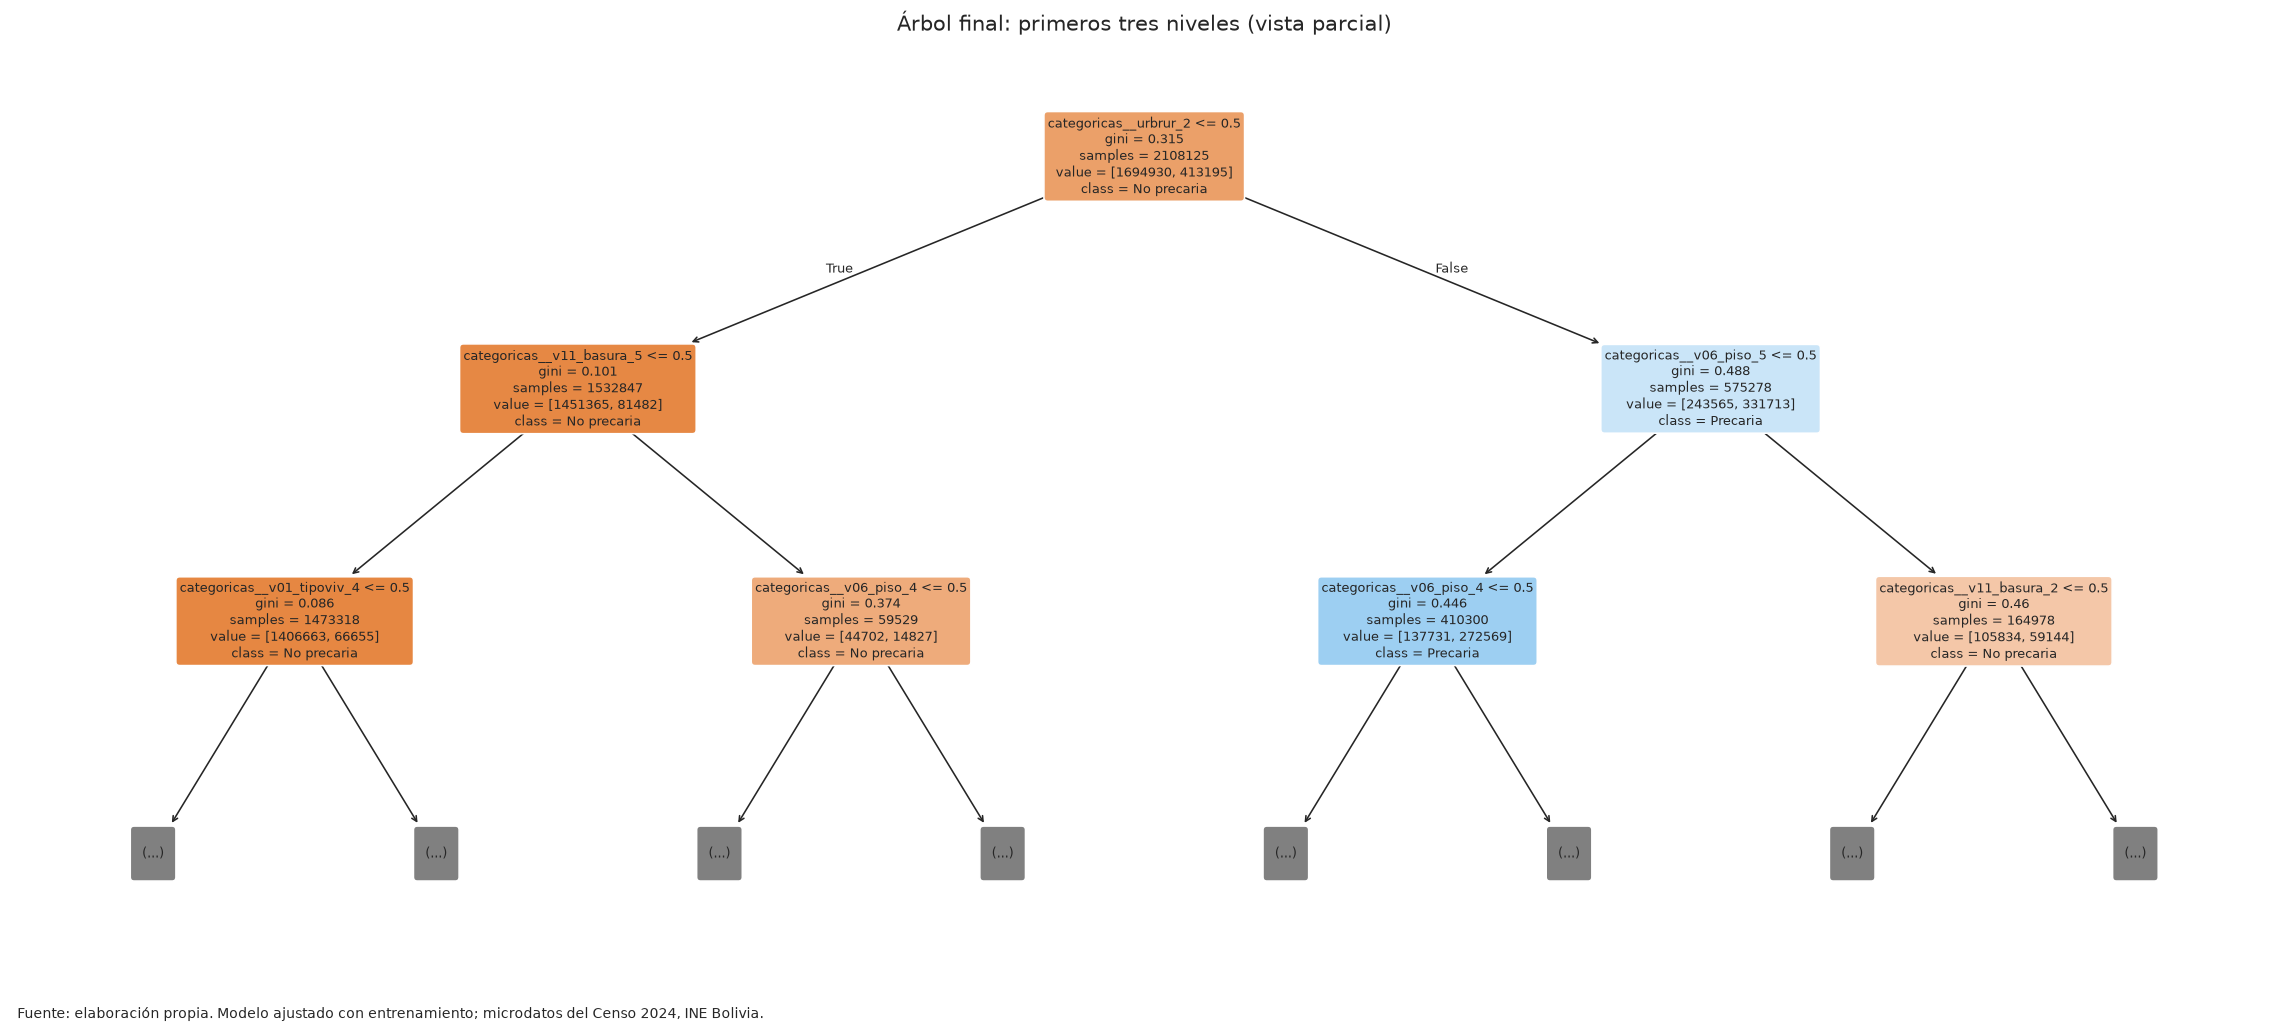

In [13]:
pre_final = modelo_final.named_steps["preprocesamiento"]
nombres_codificados = pre_final.get_feature_names_out()
assert len(nombres_codificados) == len(arbol_final.feature_importances_)
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(arbol_final, max_depth=2, feature_names=nombres_codificados,
          class_names=["No precaria", "Precaria"], filled=True, rounded=True,
          impurity=True, proportion=False, fontsize=8, ax=ax)
ax.set_title("Árbol final: primeros tres niveles (vista parcial)")
fig.text(0.01, 0.01, FUENTE_ENTRENAMIENTO, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [14]:
fila_ejemplo = X_test.iloc[[0]]
fila_codificada = pre_final.transform(fila_ejemplo)
ruta = arbol_final.decision_path(fila_codificada).indices
hoja = int(arbol_final.apply(fila_codificada)[0])
reglas = []
for nodo in ruta:
    if nodo == hoja:
        break
    indice = arbol_final.tree_.feature[nodo]
    umbral = arbol_final.tree_.threshold[nodo]
    valor = float(fila_codificada[0, indice])
    operador = "≤" if valor <= umbral else ">"
    reglas.append((int(nodo), str(nombres_codificados[indice]), valor, operador, float(umbral)))
tabla_ruta = pd.DataFrame(reglas, columns=["Nodo", "Variable codificada", "Valor", "Decisión", "Umbral"])
display(tabla_ruta)
clase_hoja = int(arbol_final.predict(fila_codificada)[0])
prob_hoja = float(arbol_final.predict_proba(fila_codificada)[0, 1])
display(Markdown(
    f"La vivienda de prueba con índice original **{fila_ejemplo.index[0]}** sigue "
    f"**{len(reglas)} divisiones** hasta la hoja **{hoja}**. En cada fila se compara "
    "el valor codificado (0 o 1) con el umbral y se toma la rama indicada. "
    f"La hoja contiene **{arbol_final.tree_.n_node_samples[hoja]:,}** registros de entrenamiento; "
    f"predice la clase **{clase_hoja}** y asigna una puntuación de clase 1 de **{prob_hoja:.4f}**. "
    "La puntuación usa ponderaciones de clase solo si la configuración seleccionada las incluye."
))

,Nodo,Variable codificada,Valor,Decisión,Umbral
0,0,categoricas__urbrur_2,0.0,≤,0.5
1,1,categoricas__v11_basura_5,0.0,≤,0.5
2,2,categoricas__v01_tipoviv_4,0.0,≤,0.5
3,3,categoricas__v14_dormit_1,0.0,≤,0.5
4,4,categoricas__v01_tipoviv_5,0.0,≤,0.5
5,5,categoricas__v01_tipoviv_6,0.0,≤,0.5
6,6,categoricas__v06_piso_4,1.0,>,0.5
7,56,categoricas__v01_tipoviv_3,0.0,≤,0.5
8,57,categoricas__tip_hog_4,1.0,>,0.5
9,149,categoricas__v13_habitac_2,0.0,≤,0.5


La vivienda de prueba con índice original **2087807** sigue **15 divisiones** hasta la hoja **168**. En cada fila se compara el valor codificado (0 o 1) con el umbral y se toma la rama indicada. La hoja contiene **24,752** registros de entrenamiento; predice la clase **0** y asigna una puntuación de clase 1 de **0.0026**. La puntuación usa ponderaciones de clase solo si la configuración seleccionada las incluye.

## 10. Importancia de las variables

`feature_importances_` suma, para cada columna codificada, la reducción ponderada de impureza producida por sus divisiones y normaliza el total a 1. Para recuperar la variable original, se agrupan por suma las columnas que creó One-Hot para cada predictor. Esta medida indica uso dentro de este árbol; puede favorecer variables con más opciones de división y no mide causalidad ni estabilidad fuera de esta muestra.

,Categoría codificada,Importancia
0,categoricas__urbrur_2,0.70142
18,categoricas__v06_piso_4,0.08023
19,categoricas__v06_piso_5,0.07181
24,categoricas__v11_basura_2,0.02833
27,categoricas__v11_basura_5,0.01543
37,categoricas__v14_dormit_1,0.01400
14,categoricas__v05_techo_4,0.01249
3,categoricas__v01_tipoviv_4,0.01189
17,categoricas__v06_piso_3,0.00946
21,categoricas__v06_piso_7,0.00791


,Variable original,Importancia
1,urbrur,0.70142
5,v06_piso,0.17473
6,v11_basura,0.04834
8,v14_dormit,0.02056
2,v01_tipoviv,0.01807
4,v05_techo,0.01480
0,tip_hog,0.00929
3,v03_pared,0.00641
9,v17_tenencia,0.00494
7,v13_habitac,0.00144


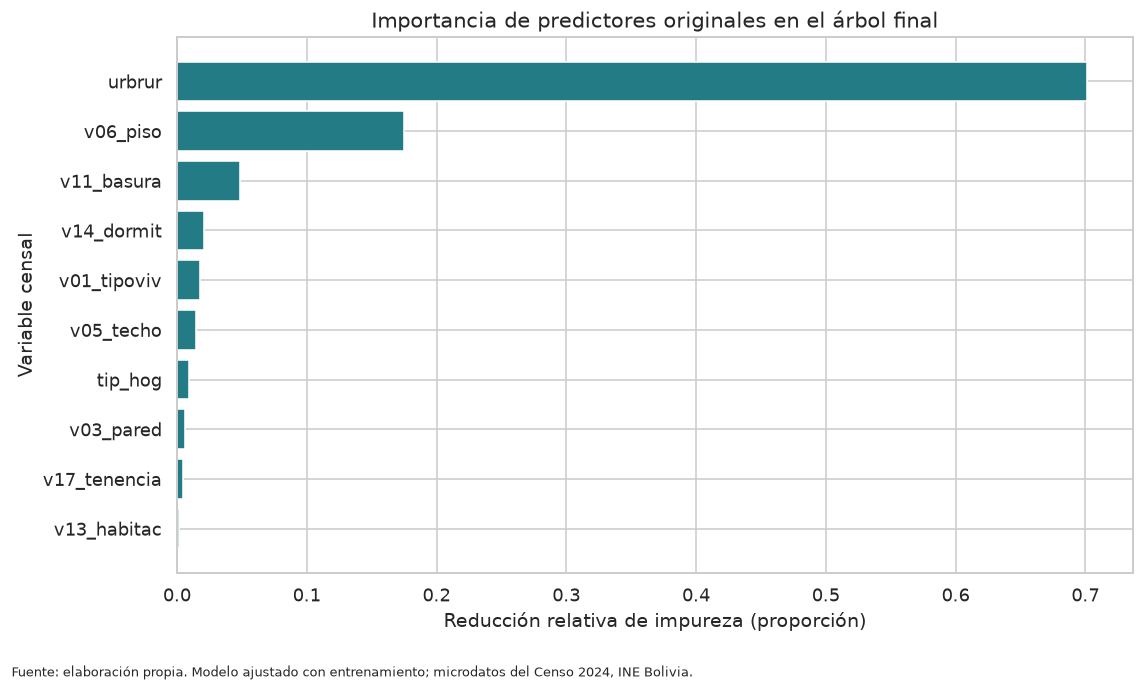

In [15]:
importancias_codificadas = pd.DataFrame({
    "Categoría codificada": nombres_codificados,
    "Importancia": arbol_final.feature_importances_
}).sort_values("Importancia", ascending=False)
encoder_final = pre_final.named_transformers_["categoricas"]
origen_codificado = []
for nombre, categorias in zip(predictoras, encoder_final.categories_):
    cantidad = len(categorias) - 1  # drop="first" omite una categoría por variable
    origen_codificado.extend([nombre] * cantidad)
assert len(origen_codificado) == len(nombres_codificados)
importancias_originales = pd.DataFrame({
    "Variable original": origen_codificado,
    "Importancia": arbol_final.feature_importances_
}).groupby("Variable original", as_index=False)["Importancia"].sum().sort_values(
    "Importancia", ascending=False)
display(importancias_codificadas.head(15).round(5))
display(importancias_originales.round(5))
assert np.isclose(importancias_originales["Importancia"].sum(), 1.0)

fig, ax = plt.subplots(figsize=(10, 6))
orden = importancias_originales.sort_values("Importancia")
ax.barh(orden["Variable original"], orden["Importancia"], color="#237b86")
ax.set(title="Importancia de predictores originales en el árbol final",
       xlabel="Reducción relativa de impureza (proporción)", ylabel="Variable censal")
fig.text(0.01, 0.01, FUENTE_ENTRENAMIENTO, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

In [16]:
top_original = importancias_originales.iloc[0]
top_codificada = importancias_codificadas.iloc[0]
display(Markdown(
    f"La variable original con mayor importancia es **`{top_original['Variable original']}`** "
    f"({top_original['Importancia']:.4f}). La categoría codificada más importante es "
    f"**`{top_codificada['Categoría codificada']}`** ({top_codificada['Importancia']:.4f}). "
    "La primera cifra suma todas sus categorías codificadas; la segunda corresponde a una sola columna. "
    "Las importancias describen la reducción de impureza dentro de este árbol, no el efecto de intervenir sobre una vivienda."
))

La variable original con mayor importancia es **`urbrur`** (0.7014). La categoría codificada más importante es **`categoricas__urbrur_2`** (0.7014). La primera cifra suma todas sus categorías codificadas; la segunda corresponde a una sola columna. Las importancias describen la reducción de impureza dentro de este árbol, no el efecto de intervenir sobre una vivienda.

## 11. Visualizaciones de desempeño

La distribución de clases se calcula sobre la población con objetivo clasificable. Las demás figuras de esta sección usan la misma prueba reservada: matriz de confusión, curva ROC y comparación del árbol predeterminado con el seleccionado. Los gráficos de importancia y estructura del árbol aparecen en las secciones 10 y 9.

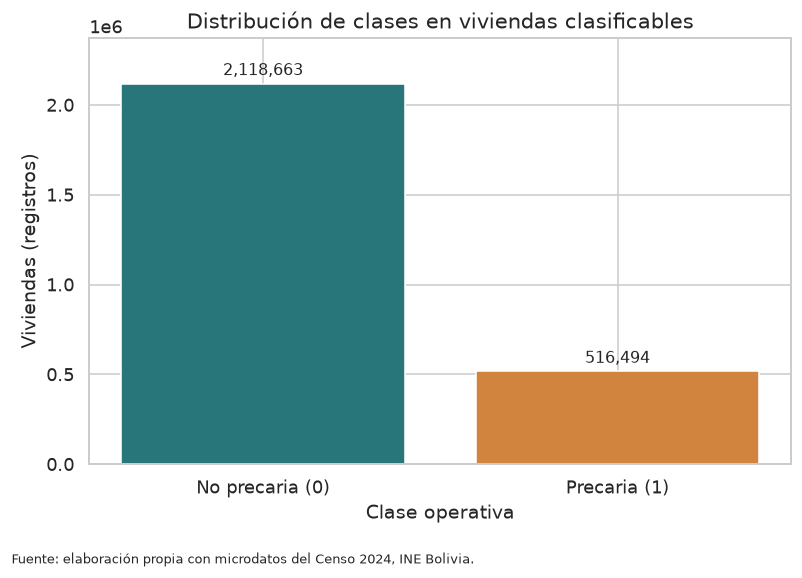

In [17]:
conteos = y.value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(["No precaria (0)", "Precaria (1)"], conteos.values,
                color=["#28767a", "#d1843d"])
ax.bar_label(barras, labels=[f"{v:,}" for v in conteos.values], padding=3)
ax.set(title="Distribución de clases en viviendas clasificables",
       ylabel="Viviendas (registros)", xlabel="Clase operativa")
ax.set_ylim(0, conteos.max() * 1.12)
fig.text(0.01, 0.01, FUENTE, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

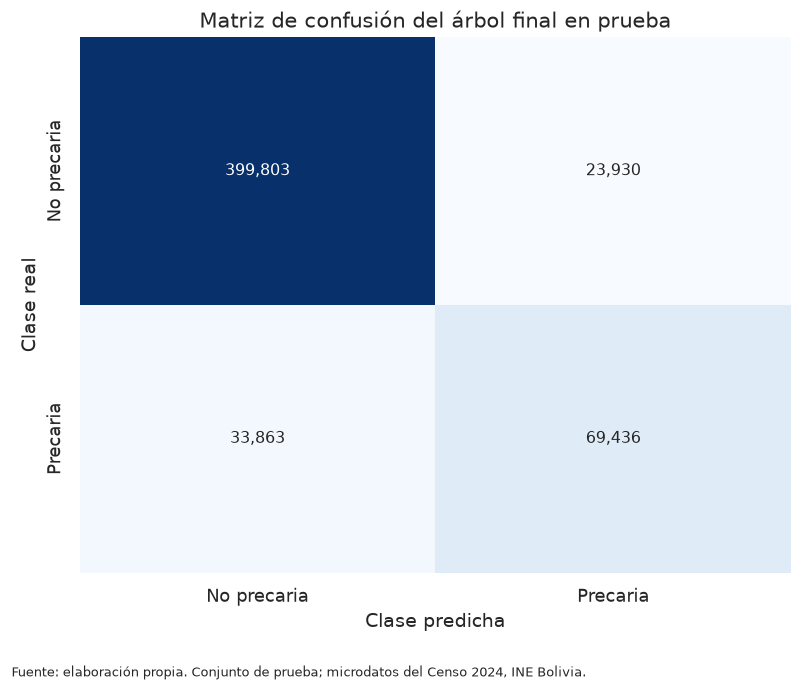

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm_final, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["No precaria", "Precaria"],
            yticklabels=["No precaria", "Precaria"])
ax.set(title="Matriz de confusión del árbol final en prueba",
       xlabel="Clase predicha", ylabel="Clase real")
fig.text(0.01, 0.01, FUENTE_PRUEBA, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

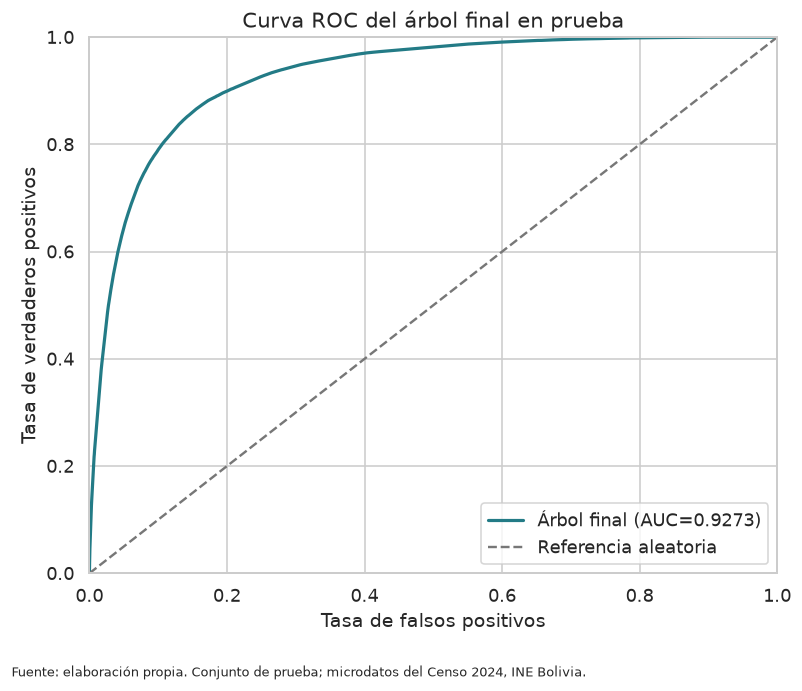

In [19]:
fpr, tpr, _ = roc_curve(y_test, prob_final)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color="#237b86", linewidth=2,
        label=f"Árbol final (AUC={metricas_test_final['ROC-AUC']:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Referencia aleatoria")
ax.set(title="Curva ROC del árbol final en prueba",
       xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos",
       xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right")
fig.text(0.01, 0.01, FUENTE_PRUEBA, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

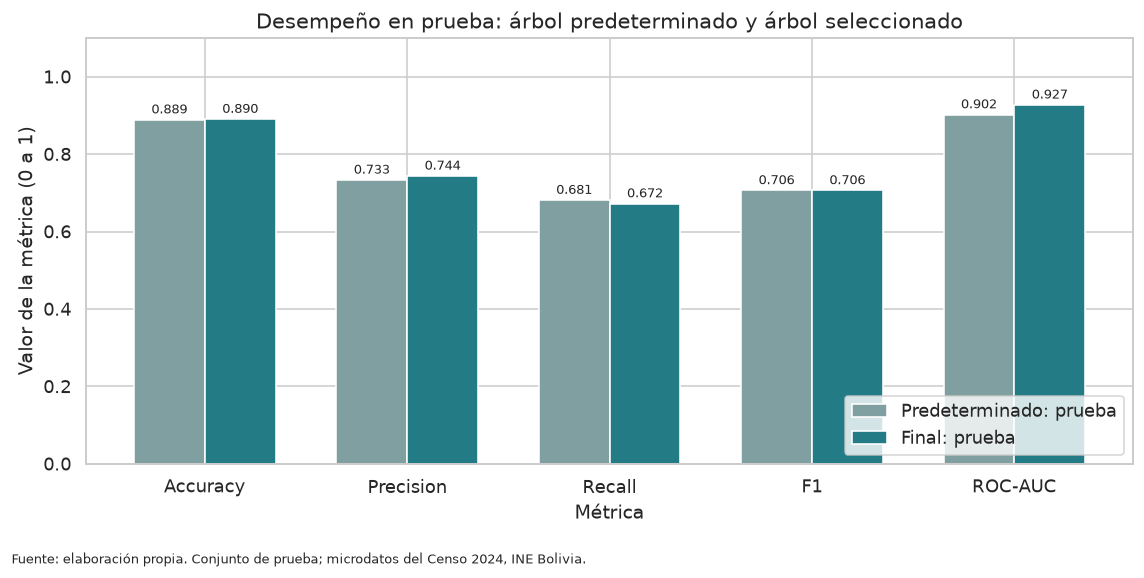

In [20]:
comparacion = tabla_metricas.loc[["Predeterminado: prueba", "Final: prueba"]]
fig, ax = plt.subplots(figsize=(10, 5))
xpos = np.arange(5)
ancho = 0.35
for desplazamiento, nombre, color in [(-ancho / 2, "Predeterminado: prueba", "#7f9fa0"),
                                     (ancho / 2, "Final: prueba", "#237b86")]:
    barras = ax.bar(xpos + desplazamiento, comparacion.loc[nombre].values,
                    width=ancho, label=nombre, color=color)
    ax.bar_label(barras, fmt="%.3f", fontsize=8, padding=2)
ax.set(title="Desempeño en prueba: árbol predeterminado y árbol seleccionado",
       ylabel="Valor de la métrica (0 a 1)", xlabel="Métrica",
       xticks=xpos, xticklabels=comparacion.columns, ylim=(0, 1.1))
ax.legend(loc="lower right")
fig.text(0.01, 0.01, FUENTE_PRUEBA, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 12. Interpretación de resultados

Las reglas y las importancias muestran asociaciones entre características censales y la clase operativa de carencia. `urbrur` permite observar una diferencia entre contextos urbanos y rurales, pero el modelo no identifica por sí mismo qué servicio falta en cada predicción. Tampoco permite atribuir diferencias a departamentos o municipios: esos códigos no son predictores y no se realizó una validación territorial externa. Una predicción positiva puede servir para **priorizar revisión** de un registro o un territorio, siempre que se contraste con las respuestas censales y los indicadores descriptivos.

El IPS informa la proporción observada con dos o más carencias entre las viviendas clasificables. Las métricas anteriores informan cuán bien el árbol reproduce esa clase en prueba. Las aplicaciones territoriales son propuestas de trabajo posterior y no resultados ya demostrados por este notebook.

En la **validación interna**, el ajuste elevó F1 de 0,7028 a 0,7047 y redujo la brecha entre ajuste y validación. En la **prueba reservada**, el F1 fue 0,7062 para el árbol predeterminado y 0,7061 para el ajustado: la diferencia es mínima y no demuestra una mejora de F1 fuera del entrenamiento. El árbol ajustado fue seleccionado antes de observar la prueba; se conserva esa decisión para evitar escoger retrospectivamente según el resultado de prueba. Su ROC-AUC de prueba fue 0,9273 frente a 0,9022 del predeterminado, mientras que su recall fue menor (0,6722 frente a 0,6811). Estas métricas muestran aspectos distintos del desempeño.

## 13. Limitaciones del modelo

El árbol puede sobreajustarse a combinaciones presentes en entrenamiento; la comparación con validación y prueba ayuda a detectar esa señal, pero no garantiza estabilidad futura. La clase 1 es minoritaria, por lo que accuracy aislada sería insuficiente y los falsos negativos requieren atención. Las reglas cambian con los hiperparámetros, especialmente profundidad y mínimos de muestras. La clase operativa depende de los códigos válidos de cuatro preguntas: las viviendas con alguna dimensión indeterminada quedan fuera. Las diez variables seleccionadas no contienen todos los factores de la precariedad y la importancia del árbol puede sesgarse hacia variables con más divisiones. Una partición aleatoria puede compartir contextos territoriales entre entrenamiento y prueba; por ello el resultado no demuestra generalización a municipios nuevos ni a otro censo.

## 14. Conclusiones

El árbol clasificó viviendas con una variable objetivo construida a partir de cuatro servicios y permitió expresar parte de la decisión mediante reglas observables. La conclusión cuantitativa se genera a continuación con las salidas efectivas de esta ejecución, para mantener la correspondencia entre texto y métricas.

In [21]:
display(Markdown(
    f"Se clasificaron **{len(y):,} viviendas** con las cuatro carencias definidas, "
    f"de las cuales **{int(y.sum()):,}** pertenecen a la clase 1. "
    f"El árbol final, de profundidad **{arbol_final.get_depth()}** y "
    f"**{arbol_final.get_n_leaves()} hojas**, obtuvo en prueba "
    f"**F1={metricas_test_final['F1']:.4f}**, "
    f"**recall={metricas_test_final['Recall']:.4f}** y "
    f"**ROC-AUC={metricas_test_final['ROC-AUC']:.4f}**. "
    f"El predictor original con más importancia fue **`{top_original['Variable original']}`**. "
    "La principal ventaja del árbol es que sus reglas pueden inspeccionarse; su límite es que esas "
    "reglas y sus importancias no prueban causalidad ni sustituyen la revisión de las respuestas originales. "
    "Como trabajo posterior conviene evaluar estabilidad temporal y territorial, calibración de puntuaciones "
    "y el costo operativo de los falsos negativos."
))

Se clasificaron **2,635,157 viviendas** con las cuatro carencias definidas, de las cuales **516,494** pertenecen a la clase 1. El árbol final, de profundidad **15** y **548 hojas**, obtuvo en prueba **F1=0.7061**, **recall=0.6722** y **ROC-AUC=0.9273**. El predictor original con más importancia fue **`urbrur`**. La principal ventaja del árbol es que sus reglas pueden inspeccionarse; su límite es que esas reglas y sus importancias no prueban causalidad ni sustituyen la revisión de las respuestas originales. Como trabajo posterior conviene evaluar estabilidad temporal y territorial, calibración de puntuaciones y el costo operativo de los falsos negativos.

## 15. Fuente de los datos

**Instituto Nacional de Estadística (INE) de Bolivia.** Microdatos oficiales del **Censo de Población y Vivienda 2024**, archivo `data/Vivienda_CPV-2024.csv`; definiciones y categorías contrastadas con `data/Diccionario de variables CPV 2024.xlsx`. Las tablas y figuras de este notebook son elaboración propia a partir de esos archivos.